## 6. What is a heatmap?
A heatmap is a visual representation of numerical data using colours.

Instead of reading every correlation value in a matrix, we can use colours to identify stronger positive or negative relationships quickly.

For example, with the coolwarm colour map:
- Red shades generally represent positive correlations.
- Blue shades generally represent negative correlations.
- Lighter shades are closer to zero.
The exact colours depend on the colour map you choose.

## 7. Create your first Seaborn heatmap


In [2]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

data = {
    "Hours_Studied": [1, 2, 3, 4, 5, 6, 7, 8],
    "Attendance": [50, 55, 60, 65, 70, 75, 80, 85],
    "Marks": [35, 40, 50, 55, 65, 70, 80, 90],
    "Sleep_Hours": [8, 7, 8, 6, 7, 6, 5, 5]
}

df = pd.DataFrame(data)

print(df)

corr = df.corr()

print(corr)

   Hours_Studied  Attendance  Marks  Sleep_Hours
0              1          50     35            8
1              2          55     40            7
2              3          60     50            8
3              4          65     55            6
4              5          70     65            7
5              6          75     70            6
6              7          80     80            5
7              8          85     90            5
               Hours_Studied  Attendance     Marks  Sleep_Hours
Hours_Studied       1.000000    1.000000  0.996464    -0.878310
Attendance          1.000000    1.000000  0.996464    -0.878310
Marks               0.996464    0.996464  1.000000    -0.857389
Sleep_Hours        -0.878310   -0.878310 -0.857389     1.000000


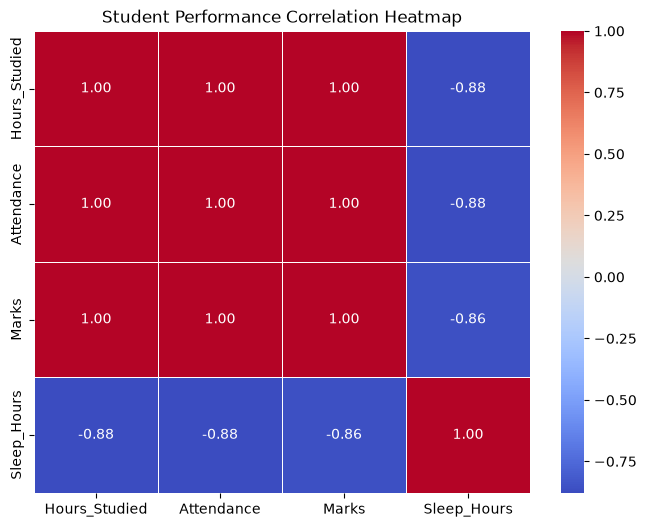

In [3]:
corr = df.corr(numeric_only=True)

fig, ax = plt.subplots(figsize=(8, 6))

sns.heatmap(
    corr,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5,
    ax=ax
)

ax.set_title("Student Performance Correlation Heatmap")

plt.show()

## Let's understand every parameter.
    Parameter	    Purpose
    data=corr	    The correlation matrix to visualise
    annot=True          Displays numerical values inside cells
    cmap="coolwarm"     Chooses the colour map
    fmt=".2f"	    Displays values to 2 decimal places
    linewidths=0.5	    Adds space/borders between cells
    ax=ax	            Draws the heatmap on our Matplotlib axes

Important: annot=True is what displays the correlation numbers inside each square. Without it, you see the colours but not the numbers.

## 8. More useful heatmap parameters
Let's cover a few more parameters you'll commonly use.

### A. vmin and vmax

Set the minimum and maximum values represented by the colour scale.

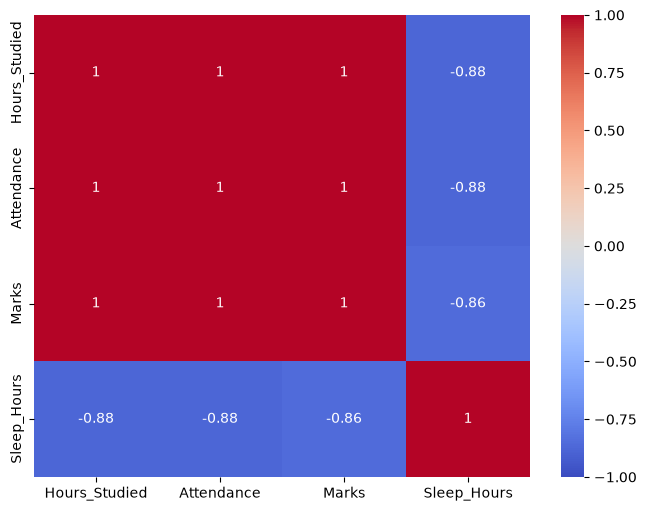

In [6]:
fig, ax = plt.subplots(figsize=(8, 6))
sns.heatmap(
    corr,
    annot=True,
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    ax=ax
)
plt.show()

Why use them?

Correlation always ranges from -1 to +1. Setting these limits keeps the colour scale consistent when comparing different heatmaps.

### B. cbar

Controls the colour bar displayed beside the heatmap.

`sns.heatmap(corr, annot=True, cbar=False, ax=ax)`

- cbar=True: displays the colour bar.
- cbar=False: hides the colour bar.

### C. square

Makes each heatmap cell square-shaped.
`sns.heatmap(corr, annot=True, square=True, ax=ax)`

## 9. How do we interpret a correlation heatmap?
Let's say our heatmap shows:
- Hours_Studied vs Marks = +0.95
- Attendance vs Marks = +0.80
- Sleep_Hours vs Marks = -0.60      
What can we understand?     
```console
Relationship	                    Interpretation
Hours studied & marks: +0.95	    Strong positive relationship
Attendance & marks: +0.80	    Strong positive relationship
Sleep hours & marks: -0.60	    Moderate negative relationship

```
For this example, students who study more tend to score higher. But remember: these are associations in the data, not proof of cause and effect.

## 10. Correlation does NOT mean causation
This is extremely important in Data Science.

Imagine:
- Ice cream sales increase.
- Swimming accidents also increase.
Does eating ice cream cause swimming accidents?

No!

Both might increase during summer because more people buy ice cream and more people go swimming.

Here, temperature could be a third variable influencing both.

So:
- Correlation = two variables are associated.
- Causation = one variable directly causes a change in another.
Never conclude causation just by looking at a heatmap

## 11. Why are heatmaps useful in Machine Learning?
One important application is understanding relationships between features before building a model.

Imagine we want to predict students' marks using:
- Hours studied
- Attendance
- Sleep hours
- Previous exam marks
A correlation heatmap helps us identify:

### A. Features related to the target

If Hours_Studied has a strong positive correlation with Marks, it may contain useful predictive information.

### B. Highly correlated input features

Suppose Hours_Studied and Study_Time_Minutes have correlation +0.99.

They may contain almost the same information.

This can indicate multicollinearity, which can cause problems for some models, particularly linear regression.

But don't automatically remove a feature just because it is highly correlated with another. Consider the model, the data and validation results.

### C. Understanding the dataset

A heatmap helps us discover patterns before starting Machine Learning.

Remember
 A correlation heatmap is an exploratory tool. It does not independently determine which features a model should use.

## 12. Complete code 

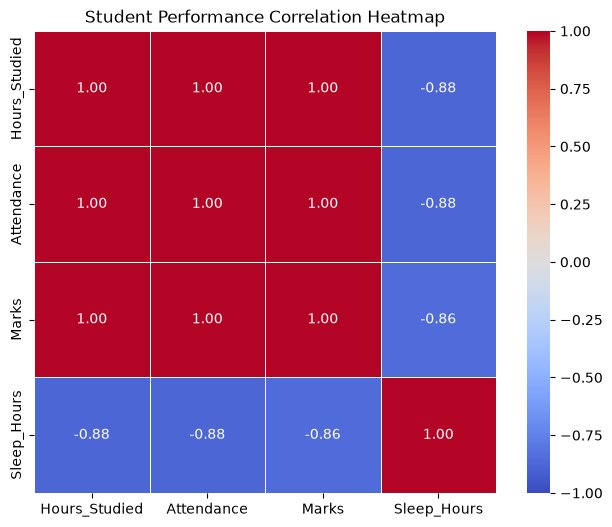

In [8]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

data = {
    "Hours_Studied": [1, 2, 3, 4, 5, 6, 7, 8],
    "Attendance": [50, 55, 60, 65, 70, 75, 80, 85],
    "Marks": [35, 40, 50, 55, 65, 70, 80, 90],
    "Sleep_Hours": [8, 7, 8, 6, 7, 6, 5, 5]
}

df = pd.DataFrame(data)

corr = df.corr(numeric_only=True)

fig, ax = plt.subplots(figsize=(8, 6))

sns.heatmap(
    corr,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5,
    vmin=-1,
    vmax=1,
    square=True,
    ax=ax
)

ax.set_title("Student Performance Correlation Heatmap")

plt.show()